# 11_1 — PPL設定の検証：西川氏の条件 → Gemma Q/K全10群

**目的**：Llama/Gemmaの未圧縮PPLを報告設定で再評価した後、GemmaでQ・Kの特異値削除によるPPL低下が評価設定に依存するか調べます。未圧縮の確認は完了し、次はQ/K削除条件を実行します。

1. `nishikawa_baseline`：両モデル、AutoModelForCausalLM → model.float()、2048、全文先頭のみBOS、非重複。報告値 **Llama 7.81 / Gemma 10.7** と比較。
2. `grid_baseline`：Gemma未圧縮、評価設定の直積24条件（※旧48条件から冗長なloader軸を統合）。
3. `qk_grid`：長さ1024/2048 × BOSなし/各ブロック先頭の4設定に限定。BF16・batch1・conditional_text固定で、Q/K × 10群 × DEなし/あり = **160回**。未圧縮4件を含む計画は164件で、同じ環境・実装の保存済み未圧縮結果を再利用します。

既存11と既存Llama分析用11_1は変更しません。旧結果と保存先を分離します。**未圧縮の確認を終えてから段階2・3へ進めてください。** これは評価の頑健性検証で、test PPLが最小になる設定を研究結果として選ぶ手順ではありません。

### 実行前に
- VS Code / Colab GPUカーネルを使用。現在のqk_gridはBF16・batch1です。未圧縮評価と同じGPU・環境なら保存済み結果を再利用できます。OOM時は条件を自動変更せず記録します。GPU割当・課金はこのノートブックでは操作しません。
- `INSTALL_DEPENDENCIES=True`で必要な場合だけインストールし、**カーネル再起動後Falseへ戻す**。Transformersを4.57.6に固定。別バージョンの比較は別カーネルで行う必要があるため本グリッドに含めません。
- 現時点では西川氏の元コード未提供。モデルrevision、初期ロード精度、バッチサイズ、attention実装など未確定の点を設定欄と出力に残します。初期ロード既定値で`model.float()`を行います。BF16ロード後のfloatと同一とは見なしません。
- 実行はユーザーが行います。`RUN_EXPERIMENTS=True`にして「すべて実行」。秘密情報は非表示入力し、保存しません。


In [1]:
from pathlib import Path
import sys, os, subprocess, getpass
INSTALL_DEPENDENCIES=False
REPO=Path('/content/RMT_utils') if Path('/content').exists() else Path.home()/'GitHub/RMT_utils'
if not (REPO/'funcs1.py').exists():
    subprocess.run(['git','clone','https://github.com/ryy1210/RMT_utils',str(REPO)],check=True)
if INSTALL_DEPENDENCIES:
    subprocess.run([sys.executable,'-m','pip','install','-r',str(REPO/'requirements-notebooks.txt'),'transformers==4.57.6'],check=True)
    raise RuntimeError('インストール完了。カーネル再起動後INSTALL_DEPENDENCIES=Falseで再開してください')
sys.path.insert(0,str(REPO))


## 1. 実行設定

現在は`PHASE='qk_grid'`、`RUN_EXPERIMENTS=True`。上から「すべて実行」でGemmaのQ/K削除比較に進みます。`BASELINE_MODELS`はnishikawa_baseline専用で、この段階ではLlamaを読み込みません。

実行する軸：長さ1024/2048、BOSなし/各ブロック先頭。BF16、batch1、conditional_textに固定します。全10群とDEなし/ありは維持します。全文先頭のみBOS・FP32・batch2の保存済み結果はそのまま残ります。

- グリッドのFP32は**BF16ロード後にfloat()**。11と同じ元重み・同じ削除重みを使い推論精度だけを変えます。西川氏比較段階の初期ロード既定値とは別です。
- 第1群は最小側、第10群は最大側。各Q/Kモジュールの全Transformerブロックで同じ群を同時削除。DE後は元座標へ戻します。
- BOSなし/全文先頭のみはLトークン、各ブロックBOSはL-1個の内容+BOSで総長L。BOS自身は採点しません。境界と末尾切り捨て・採点対象は条件間で変わるため、その差も記録し「同一トークン位置の純粋BOS効果」とは呼びません。


In [2]:
import json, hashlib, math, gc, time, re, platform, importlib.metadata, itertools, unicodedata
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
import funcs1
from funcs1 import _dyson_from_svd
RUN_EXPERIMENTS=True  # Trueにしてユーザー側で実行
PHASE='qk_grid'  # 未圧縮の確認後、Gemma Q/Kの全10群を比較
BASELINE_MODELS=['llama','gemma']
NISHIKAWA_LOAD_PRECISION='default'  # default / bf16 / fp32。提示コードの初期精度は未確定。
NISHIKAWA_BATCH=2  # 西川氏の実際のbatchは未確認
TRANSFORMERS_VERSION='4.57.6'
ATTENTION='sdpa'  # 西川氏の実装は未確認。記録し、勝手にfallbackしない。
DEVICE='cuda'; SVD_DEVICE='cuda'
MODELS={'llama':'meta-llama/Llama-3.2-3B','gemma':'google/gemma-3-4b-pt'}
REVISIONS={'llama':'13afe5124825b4f3751f836b40dafda64c1ed062','gemma':'cc012e0a6d0787b4adcc0fa2c4da74402494554d'}
TOTAL={'llama':3212749824,'gemma':3880263168}
LENGTHS=[1024,2048]
# 2026-11-07: baseline比較を受けて4設定へ限定（削除条件160回＋未圧縮4回）。
BOS_MODES=['none','each_block']
PRECISIONS=['bf16']
# 同じテキストモデルを抽出するconditional_textに固定。既存の読み込み実装は維持。
LOADERS=['conditional_text']
BATCH_SIZES=[1]
GROUPS=['Q','K']; DECILES=list(range(1,11)); DE_OPTIONS=[False,True]
MOUNT_DRIVE=True
if Path('/content').exists():
    if MOUNT_DRIVE and RUN_EXPERIMENTS:
        from google.colab import drive
        drive.mount('/content/drive')
    DATA_ROOT=Path('/content/drive/MyDrive/TUS/hashiguchi/data')
else:
    base=Path.home()/'Library/CloudStorage/GoogleDrive-ryoya.zushi1210@gmail.com'
    candidates=[p/'TUS/hashiguchi/data' for p in base.iterdir() if unicodedata.normalize('NFC',p.name)=='マイドライブ']
    if len(candidates)!=1:raise FileNotFoundError('DATA_ROOTを設定してください')
    DATA_ROOT=candidates[0]
LEGACY=DATA_ROOT/'ibis2026_de_lra'/'ibis2026-de-controlled-v2-bulk-order'
OUTPUT=DATA_ROOT/'ibis2026_de_lra'/'gemma-qk-ppl-settings-grid-v1'
# SVDキャッシュも永続化。残容量に注意（数GB以上）。不要になったらユーザーが削除可能。
CACHE=OUTPUT/'svd_cache'
if RUN_EXPERIMENTS and not os.environ.get('HF_TOKEN'):
    token=getpass.getpass('HF_TOKEN (cached loginなら空欄): ')
    if token:os.environ['HF_TOKEN']=token
n_settings=len(LENGTHS)*len(BOS_MODES)*len(PRECISIONS)*len(LOADERS)*len(BATCH_SIZES)
print('phase:',PHASE,'; grid settings:',n_settings,'; full grid PPL evaluations:',n_settings*(1+len(GROUPS)*len(DECILES)*len(DE_OPTIONS)))
print('Output:',OUTPUT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
phase: qk_grid ; grid settings: 4 ; full grid PPL evaluations: 164
Output: /content/drive/MyDrive/TUS/hashiguchi/data/ibis2026_de_lra/gemma-qk-ppl-settings-grid-v1


## 2. 評価・保存・削除の実装

保存済み08_2の「BOSなし1024」トークンと再取得したWikiText-2が一致することを確認してから評価します。モデルrevision、データrevision、トークンハッシュ、環境、実装、各条件を結果IDに含めます。環境が変わった結果を同一条件として自動流用しません。

PPLは全採点トークンの平均交差エントロピーのexp。集計はFP64、交差エントロピーはFP32。paddingなし、各ブロック最初のトークンは採点対象外。バッチ別PPLの平均ではありません。

完了結果は損失チェックサムも照合してスキップ。SVD/DEキャッシュは元重みのハッシュを照合。メモリ不足は失敗記録とし、精度・batchを自動変更しません。モデル読込のキー不一致は不完全なモデルで評価せず失敗にします。


In [3]:
# 11_1専用: 評価条件を保存し、同条件の未圧縮PPLとだけ比較する。
def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False, default=lambda x: x.item()).encode()).hexdigest()

def file_hash(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda: f.read(8*1024*1024), b''): h.update(b)
    return h.hexdigest()

def write_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix('.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False))
    tmp.replace(path)

def safe_exp(x):
    return math.exp(x) if x < 709 else None

def pack_tokens(raw, length, bos_mode, bos_id):
    """No EOS insertion/padding. each_block uses L-1 content tokens + one BOS."""
    raw = np.asarray(raw, dtype=np.int64)
    if length < 2 or bos_mode not in ('none', 'first_only', 'each_block'):
        raise ValueError('Invalid packing specification')
    if bos_mode == 'each_block':
        n = len(raw)//(length-1)
        a = np.empty((n, length), dtype=np.int64); a[:, 0] = bos_id
        a[:, 1:] = raw[:n*(length-1)].reshape(n, length-1)
        dropped = len(raw)-n*(length-1)
    else:
        ids = np.r_[bos_id, raw] if bos_mode == 'first_only' else raw
        n = len(ids)//length; a = ids[:n*length].reshape(n, length).copy()
        dropped = len(ids)-n*length
    if not len(a): raise ValueError('No complete evaluation blocks')
    return a, dict(blocks=len(a), length=length, bos_mode=bos_mode,
                   bos_count=int((a == bos_id).sum()), scored_tokens=len(a)*(length-1),
                   dropped_tokens=dropped)

@torch.inference_mode()
def evaluate(model, tokens, batch_size):
    """Same full logits forward as 11; FP32 CE, FP64 sums; save prefix-position losses."""
    model.eval(); device = next(model.parameters()).device
    loss_sums=[]; counts=[]
    positions=np.zeros(tokens.shape[1]-1, dtype=np.float64)
    for start in range(0, len(tokens), batch_size):
        ids=torch.as_tensor(tokens[start:start+batch_size],device=device)
        logits=model(input_ids=ids,use_cache=False).logits
        sums=torch.zeros(len(ids),device=device,dtype=torch.float64)
        for pos in range(0, ids.shape[1]-1, 64):
            end=min(pos+64, ids.shape[1]-1)
            loss=F.cross_entropy(logits[:,pos:end].float().transpose(1,2),ids[:,pos+1:end+1],reduction='none')
            if not torch.isfinite(loss).all(): raise FloatingPointError('Nonfinite loss')
            sums+=loss.double().sum(1)
            positions[pos:end]+=loss.double().sum(0).cpu().numpy()
        loss_sums.extend(sums.cpu().tolist()); counts.extend([ids.shape[1]-1]*len(ids))
        del logits
        if start == 0 or (start//batch_size+1)%25 == 0:
            print(f'  blocks {min(start+batch_size,len(tokens))}/{len(tokens)}',flush=True)
    return np.asarray(loss_sums),np.asarray(counts),positions

def check_loading(info):
    bad={k:info.get(k) for k in ('missing_keys','unexpected_keys','mismatched_keys','error_msgs') if info.get(k)}
    if bad: raise RuntimeError(f'Checkpoint loading mismatch: {bad}')

def extract_text(full):
    from transformers import Gemma3ForCausalLM
    with torch.device('meta'): text=Gemma3ForCausalLM(full.config.text_config)
    text.model=full.model.language_model; text.lm_head=full.lm_head
    text.generation_config=full.generation_config
    return text

def load_model(key, loader, load_precision):
    from transformers import AutoModelForCausalLM, Gemma3ForConditionalGeneration
    kwargs=dict(revision=REVISIONS[key],token=os.environ.get('HF_TOKEN'),
                low_cpu_mem_usage=True,output_loading_info=True,attn_implementation=ATTENTION)
    # defaultはtorch_dtypeを指定しない西川氏の提示コード。autoとは別物。
    if load_precision!='default':
        kwargs['torch_dtype']={'bf16':torch.bfloat16,'fp32':torch.float32}[load_precision]
# [修正ログ 2026-11-07]
# google/gemma-3-4b-pt はマルチモーダル構成であり、loader=='auto' (AutoModelForCausalLM.from_pretrained)
# でも内部的に Gemma3ForConditionalGeneration (視覚層込み 4,300,079,472 パラメータ) がロードされる。
# これまでの実験と同様に Gemma を言語モデルとしてのみ扱い (3,880,263,168 パラメータ)、
# Parameter count 4300079472 != 3880263168 エラーおよび不要な視覚層のVRAM消費を防ぐため、
# loader=='auto' かつ key=='gemma' の場合にも extract_text() で言語モデル部分を抽出するよう修正。
# 旧コード:
# if loader=='auto': model,info=AutoModelForCausalLM.from_pretrained(MODELS[key],**kwargs)
# elif loader=='conditional_text' and key=='gemma':
#     full,info=Gemma3ForConditionalGeneration.from_pretrained(MODELS[key],**kwargs)
#     model=extract_text(full); del full; gc.collect()
    if loader=='auto':
        full,info=AutoModelForCausalLM.from_pretrained(MODELS[key],**kwargs)
        model=extract_text(full) if key=='gemma' else full
        if key=='gemma': del full; gc.collect()
    elif loader=='conditional_text' and key=='gemma':
        full,info=Gemma3ForConditionalGeneration.from_pretrained(MODELS[key],**kwargs)
        model=extract_text(full); del full; gc.collect()
    else: raise ValueError('Unsupported loader')
    check_loading(info)
    if any(x.is_meta for x in list(model.parameters())+list(model.buffers())): raise RuntimeError('Meta tensors remain')
    count=sum(x.numel() for x in model.parameters())
    if count!=TOTAL[key]: raise RuntimeError(f'Parameter count {count} != {TOTAL[key]}')
    model.eval(); model.config.use_cache=False
    report=dict(model=MODELS[key],revision=REVISIONS[key],loader=loader,load_precision=load_precision,
                parameter_count=count,parameter_dtypes=sorted({str(p.dtype) for p in model.parameters()}),
                config=model.config.to_dict(),loading_info=info)
    return model,report

def prepare_data(key):
    """Persist exact corpus; assert no-BOS 1024 equals the archived 08_2 input."""
    from transformers import AutoTokenizer
    from datasets import load_dataset
    from huggingface_hub import HfApi
    root=OUTPUT/'inputs'; root.mkdir(parents=True,exist_ok=True)
    text_path=root/'wikitext2_test.txt'; receipt=root/'dataset.json'
    if receipt.exists():
        r=json.loads(receipt.read_text())
        if file_hash(text_path)!=r['text_sha256']: raise ValueError('Corpus checksum mismatch')
    else:
        revision=HfApi().dataset_info('Salesforce/wikitext').sha
        ds=load_dataset('Salesforce/wikitext','wikitext-2-raw-v1',split='test',revision=revision)
        text_path.write_text('\n\n'.join(ds['text']),encoding='utf-8')
        r=dict(dataset='Salesforce/wikitext',subset='wikitext-2-raw-v1',split='test',revision=revision,
               fingerprint=ds._fingerprint,text_sha256=file_hash(text_path))
        write_json(receipt,r)
    tok=AutoTokenizer.from_pretrained(MODELS[key],revision=REVISIONS[key],token=os.environ.get('HF_TOKEN'))
    text=text_path.read_text(encoding='utf-8')
    raw=np.asarray(tok(text,add_special_tokens=False)['input_ids'],dtype=np.int64)
    with_special=np.asarray(tok(text,add_special_tokens=True)['input_ids'],dtype=np.int64)
    if not np.array_equal(with_special,np.r_[tok.bos_token_id,raw]):
        raise ValueError('既定special tokensが先頭BOSのみと異なります。西川氏のtokenizer設定を確認してください')
    reference=LEGACY/f'{key}_tokens.npy'
    if not reference.exists(): raise FileNotFoundError(f'08_2 input required to verify corpus: {reference}')
    check,_=pack_tokens(raw,1024,'none',tok.bos_token_id)
    if not np.array_equal(check,np.load(reference,allow_pickle=False)):
        raise ValueError('再取得したtest tokensが08_2と不一致。データ差を解決してから再開してください')
    result={}
    for length,bos in itertools.product(sorted(set(LENGTHS+[2048])),sorted(set(BOS_MODES+['first_only']))):
        a,meta=pack_tokens(raw,length,bos,tok.bos_token_id)
        p=root/f'{key}_{length}_{bos}.npy'
        if p.exists():
            if not np.array_equal(np.load(p,allow_pickle=False),a): raise ValueError('Stored tokens differ')
        else:
            with p.with_suffix('.tmp').open('wb') as f: np.save(f,a)
            p.with_suffix('.tmp').replace(p)
        meta.update(model=MODELS[key],revision=REVISIONS[key],bos_token_id=tok.bos_token_id,
                    corpus=r,sha256=file_hash(p))
        write_json(p.with_suffix('.json'),meta)
        result[(length,bos)]=(a,meta)
    return result

def environment():
    return dict(python=platform.python_version(),versions={k:importlib.metadata.version(k) for k in
                ('torch','transformers','datasets','numpy')},gpu=torch.cuda.get_device_name() if torch.cuda.is_available() else 'cpu',
                cuda=torch.version.cuda,attention=ATTENTION,tf32=False)

def implementation_hash():
    # Runtime functions fingerprint excludes Jupyter cell IDs/filenames.
    import types
    def code(c):
        return [c.co_code.hex(),c.co_names,c.co_varnames,[code(v) if isinstance(v,types.CodeType) else repr(v) for v in c.co_consts]]
    names=['pack_tokens','evaluate','load_model','extract_text','decompose','reconstruct','get_parts','apply_condition','evaluate_job','cast_eval','snapshot_buffers','targets','restore','prepare_data']
    return digest({n:code(getattr(globals()[n],'__wrapped__',globals()[n]).__code__) for n in names})

def make_spec(key,protocol,setting,condition,token_meta,weight_id):
    return dict(protocol=protocol,model=key,model_id=MODELS[key],revision=REVISIONS[key],
                setting=setting,condition=condition,tokens=token_meta,weights=weight_id,
                environment=ENV,implementation=IMPLEMENTATION,funcs1_sha256=file_hash(Path(funcs1.__file__)))

def result_path(spec): return OUTPUT/'jobs'/digest(spec)

def read_result(spec):
    p=result_path(spec); receipt=p/'summary.json'
    if not receipt.exists(): return None
    obj=json.loads(receipt.read_text())
    if obj['spec']!=spec or obj['status']!='ok': raise ValueError('Result identity mismatch')
    if file_hash(p/'losses.npz')!=obj['loss_sha256']: raise ValueError('Loss checksum mismatch')
    with np.load(p/'losses.npz',allow_pickle=False) as a:
        loss=a['loss']; counts=a['count']
        if len(loss)!=spec['tokens']['blocks'] or not np.all(counts==spec['setting']['length']-1):
            raise ValueError('Evaluation coverage mismatch')
        if not np.isfinite(loss).all(): raise ValueError('Nonfinite saved losses')
        value=safe_exp(float(loss.sum()/counts.sum()))
        if value!=obj['ppl']: raise ValueError('PPL receipt mismatch')
    return obj

def failure(spec,exc):
    # Do not save full tracebacks / credential-bearing HTTP URLs.
    msg=re.sub(r'hf_[A-Za-z0-9]+','[REDACTED]',str(exc))[:1200]
    write_json(result_path(spec)/'failure.json',dict(spec=spec,status='failed',exception=type(exc).__name__,message=msg))
    print('FAILED:',type(exc).__name__,msg,flush=True)

def evaluate_job(model,spec,tokens):
    old=read_result(spec)
    if old is not None: return old
    p=result_path(spec); p.mkdir(parents=True,exist_ok=True); started=time.time()
    print(spec['protocol'],spec['model'],spec['condition'],spec['setting'],flush=True)
    try:
        loss,count,positions=evaluate(model,tokens,spec['setting']['batch'])
        with (p/'losses.tmp').open('wb') as f:
            np.savez_compressed(f,loss=loss,count=count,position_loss_sum=positions,position_count=np.full(len(positions),len(tokens)))
        (p/'losses.tmp').replace(p/'losses.npz')
        obj=dict(spec=spec,status='ok',ppl=safe_exp(float(loss.sum()/count.sum())),
                 ppl_overflow=float(loss.sum()/count.sum())>=709,scored_tokens=int(count.sum()),loss_sha256=file_hash(p/'losses.npz'),seconds=time.time()-started)
        write_json(p/'summary.json',obj)
        if (p/'failure.json').exists(): (p/'failure.json').unlink()
        print('SAVED PPL:',obj['ppl'],flush=True)
        return obj
    except torch.cuda.OutOfMemoryError as e:
        failure(spec,e);gc.collect();torch.cuda.empty_cache();return None
    # Other errors stop: do not silently change the model or data to make a run succeed.

# Same DE, SVD orientation, and ascending decile definition as 11.
def decompose(weight):
    transposed=weight.shape[0]>weight.shape[1]
    w=(weight.T if transposed else weight).float().to(SVD_DEVICE)
    u,s,v=torch.linalg.svd(w,full_matrices=False)
    y,x,z=_dyson_from_svd(w.cpu().double().numpy(),u.cpu().double().numpy(),s.cpu().double().numpy(),v.cpu().double().numpy())
    ud,sd,vd=torch.linalg.svd(torch.as_tensor(y,device=SVD_DEVICE,dtype=torch.float32),full_matrices=False)
    return {False:(u,s,v,None,None,transposed),True:(ud,sd,vd,x,z,transposed)}

def reconstruct(parts,indices):
    u,s,v,x,z,t=parts; device=u.device
    idx=torch.as_tensor(indices,device=device,dtype=torch.long)
    result=(u[:,idx]*s[idx])@v[idx,:]
    if x is not None:
        result*=torch.as_tensor(np.sqrt(x),device=device,dtype=result.dtype)[:,None]
        result*=torch.as_tensor(np.sqrt(z),device=device,dtype=result.dtype)[None,:]
    return result.T if t else result

def tensor_hash(w): return hashlib.sha256(w.detach().cpu().contiguous().view(torch.uint8).numpy().tobytes()).hexdigest()

def targets(model,group):
    suffix={'Q':'q_proj','K':'k_proj'}[group]
    rows=[(n,m) for n,m in model.named_modules() if isinstance(m,torch.nn.Linear) and n.split('.')[-1]==suffix]
    blocks=[int(re.search(r'layers\.(\d+)\.',n).group(1)) for n,_ in rows]
    if sorted(blocks)!=list(range(model.config.num_hidden_layers)): raise ValueError('Missing/duplicate target layer')
    return rows

def get_parts(name,weight):
    identity=dict(name=name,shape=list(weight.shape),original_sha256=tensor_hash(weight),revision=REVISIONS['gemma'],
                  implementation=IMPLEMENTATION,funcs1_sha256=file_hash(Path(funcs1.__file__)),torch=torch.__version__,svd_device=SVD_DEVICE)
    p=CACHE/digest(identity); receipt=p.with_suffix('.json'); data=p.with_suffix('.pt')
    if receipt.exists() and data.exists():
        r=json.loads(receipt.read_text())
        if r['identity']!=identity or r['sha256']!=file_hash(data): raise ValueError('SVD cache mismatch')
        return torch.load(data,map_location='cpu',weights_only=True)
    CACHE.mkdir(parents=True,exist_ok=True)
    print('SVD / DE:',name,flush=True)
    parts=decompose(weight)
    stored={de:(u.cpu(),s.cpu(),v.cpu(),None if x is None else torch.as_tensor(np.asarray(x).copy()),
                None if z is None else torch.as_tensor(np.asarray(z).copy()),t) for de,(u,s,v,x,z,t) in parts.items()}
    torch.save(stored,p.with_suffix('.tmp'));p.with_suffix('.tmp').replace(data)
    write_json(receipt,dict(identity=identity,sha256=file_hash(data)))
    del parts;gc.collect();torch.cuda.empty_cache()
    return stored

@torch.no_grad()
def apply_condition(rows,originals,condition):
    # 11と同じBF16元重み・FP32 SVDから変更重みを作りBF16に丸める。
    # FP32評価でもこの同じ変更重みをfloatへ拡張し、削除操作の差を混入させない。
    records=[]
    for name,module in rows:
        stored=get_parts(name,originals[name]);u,s,v,x,z,t=stored[condition['de']]
        idx=np.array_split(np.arange(len(s)-1,-1,-1),10)[condition['decile']-1]
        parts=(u.to(SVD_DEVICE),s.to(SVD_DEVICE),v.to(SVD_DEVICE),x,z,t)
        removed=reconstruct(parts,idx).cpu()
        new=(originals[name].float()-removed).to(torch.bfloat16)
        if not torch.isfinite(new).all(): raise FloatingPointError('Nonfinite pruned weights')
        module.weight.copy_(new.to(module.weight.device,dtype=module.weight.dtype))
        records.append(dict(name=name,rank=len(s),removed=len(idx),original_sha256=tensor_hash(originals[name]),pruned_sha256=tensor_hash(new)))
        del stored,parts,removed,new
    return records

@torch.no_grad()
def restore(rows,originals):
    for name,module in rows: module.weight.copy_(originals[name].to(module.weight.device,dtype=module.weight.dtype))

def snapshot_buffers(model):
    return {n:b.detach().cpu().clone() for n,b in model.named_buffers() if b.is_floating_point()}

def cast_eval(model,precision,buffers):
    # Preserve original FP32 rotary buffers when switching back to BF16 parameters.
    model.float() if precision=='fp32' else model.bfloat16()
    for name,original in buffers.items():
        parent,_,leaf=name.rpartition('.')
        owner=model.get_submodule(parent) if parent else model
        device=getattr(owner,leaf).device
        value=original.float() if precision=='fp32' else original
        setattr(owner,leaf,value.to(device).clone())
    return model


def run_nishikawa():
    for key in BASELINE_MODELS:
        inputs=prepare_data(key);a,meta=inputs[(2048,'first_only')]
        setting=dict(length=2048,bos='first_only',precision='fp32',batch=NISHIKAWA_BATCH,loader='auto',load_precision=NISHIKAWA_LOAD_PRECISION)
        spec=make_spec(key,'nishikawa_reported',setting,dict(group='baseline',de=False,decile=0),meta,
                       dict(load_precision=NISHIKAWA_LOAD_PRECISION,cast='model.float()',deletion='none'))
        if read_result(spec): print('SKIP Nishikawa baseline',key);continue
        model=None
        try:
            model,report=load_model(key,'auto',NISHIKAWA_LOAD_PRECISION)
            write_json(result_path(spec)/'loading_report.json',report)
            model=model.float().to(DEVICE)
            evaluate_job(model,spec,a)
        except Exception as e:
            failure(spec,e)
        finally:
            del model;gc.collect();torch.cuda.empty_cache()

def grid_settings(loader):
    return [dict(length=l,bos=b,precision=p,batch=n,loader=loader,load_precision='bf16')
            for p,l,b,n in itertools.product(PRECISIONS,LENGTHS,BOS_MODES,BATCH_SIZES)]

def run_grid():
    inputs=prepare_data('gemma')
    conditions=[dict(group='baseline',de=False,decile=0)]
    if PHASE=='qk_grid': conditions += [dict(group=g,de=d,decile=k) for g,d,k in itertools.product(GROUPS,DE_OPTIONS,DECILES)]
    weight_id=dict(load_precision='bf16',pruning='11 BF16 originals / FP32 SVD / BF16 pruned weights; identical for both eval precisions')
    planned=[]
    for loader in LOADERS:
        for c in conditions:
            for s in grid_settings(loader):
                spec=make_spec('gemma','gemma_grid',s,c,inputs[(s['length'],s['bos'])][1],weight_id)
                planned.append(dict(job_id=digest(spec),condition=c,setting=s))
    write_json(OUTPUT/f'planned_{PHASE}_{digest(ENV)[:12]}.json',planned)
    for loader in LOADERS:
        settings=grid_settings(loader)
        jobs=[(c,s,make_spec('gemma','gemma_grid',s,c,inputs[(s['length'],s['bos'])][1],weight_id)) for c in conditions for s in settings]
        if all(read_result(spec) is not None for _,_,spec in jobs): print('SKIP whole loader:',loader);continue
        model=None
        try:
            model,report=load_model('gemma',loader,'bf16');model=model.to(DEVICE)
            buffers=snapshot_buffers(model)
            write_json(OUTPUT/'loading'/f'{loader}_{digest(ENV)[:12]}.json',report)
            # Compare all model weights across loaders before claiming a pure loader comparison.
            wh={n:tensor_hash(p) for n,p in model.named_parameters()}
            ref=OUTPUT/'loading'/'canonical_model_weights.json'
            if ref.exists() and json.loads(ref.read_text())!=wh: raise ValueError('Loader changed model weights; stop comparison')
            write_json(ref,wh)
            for c in conditions:
                todo=[(s,spec) for cc,s,spec in jobs if cc==c and read_result(spec) is None]
                if not todo: continue
                rows=[]; originals={}
                try:
                    model=cast_eval(model,'bf16',buffers)
                    if c['group']!='baseline':
                        rows=targets(model,c['group']);originals={n:m.weight.detach().cpu().clone() for n,m in rows}
                        records=apply_condition(rows,originals,c)
                        write_json(OUTPUT/'deletions'/f'{loader}_{c["group"]}_{int(c["de"])}_{c["decile"]:02d}.json',records)
                    for s,spec in todo:
                        model=cast_eval(model,s['precision'],buffers)
                        # load_precision is always BF16 here; no automatic precision/batch fallback on OOM.
                        evaluate_job(model,spec,inputs[(s['length'],s['bos'])][0])
                finally:
                    restore(rows,originals); del originals;gc.collect();torch.cuda.empty_cache()
        except Exception as e:
            for _,_,spec in jobs:
                if read_result(spec) is None: failure(spec,e)
            print('Loader branch stopped; other loader remains independently testable.')
        finally:
            del model;gc.collect();torch.cuda.empty_cache()
    write_json(OUTPUT/f'planned_{PHASE}_{digest(ENV)[:12]}.json',planned)


def run():
    global ENV,IMPLEMENTATION
    if importlib.metadata.version('transformers')!=TRANSFORMERS_VERSION:
        raise RuntimeError(f'Transformers {TRANSFORMERS_VERSION}をインストール後、カーネルを再起動してください')
    if DEVICE!='cuda' or not torch.cuda.is_available(): raise RuntimeError('本番はCUDA GPUが必要です')
    torch.manual_seed(17); np.random.seed(17)
    torch.backends.cuda.matmul.allow_tf32=False;torch.backends.cudnn.allow_tf32=False
    ENV=environment(); IMPLEMENTATION=implementation_hash()
    OUTPUT.mkdir(parents=True,exist_ok=True)
    write_json(OUTPUT/'environments'/f'{digest(ENV)}.json',ENV)
    if PHASE=='nishikawa_baseline': run_nishikawa()
    elif PHASE in ('grid_baseline','qk_grid'): run_grid()
    else: raise ValueError('Unknown PHASE')


## 3. 実行

`RUN_EXPERIMENTS=False`では何も推論しません。設定変更後は上から再実行してください。
途中停止は次回同じ条件で完了済み結果をスキップし、失敗・未完了条件のみ再試行します。
新しいGPU/ライブラリ環境は別結果として保存します。全探索には長時間かかります。未圧縮比較の結果はこの後の分析セルで確認できます。


In [4]:
if RUN_EXPERIMENTS:
    run()
else:
    print('本番未実行。設定を確認してRUN_EXPERIMENTS=Trueにしてください。')

tokenizer_config.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

... (7 outputs left out)

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

gemma_grid gemma {'group': 'baseline', 'de': False, 'decile': 0} {'length': 1024, 'bos': 'none', 'precision': 'bf16', 'batch': 1, 'loader': 'conditional_text', 'load_precision': 'bf16'}
  blocks 1/285
  blocks 25/285
  blocks 50/285
  blocks 75/285
  blocks 100/285
  blocks 125/285
  blocks 150/285
  blocks 175/285
  blocks 200/285
  blocks 225/285
  blocks 250/285
  blocks 275/285
SAVED PPL: 16.479485550262122
gemma_grid gemma {'group': 'baseline', 'de': False, 'decile': 0} {'length': 1024, 'bos': 'each_block', 'precision': 'bf16', 'batch': 1, 'loader': 'conditional_text', 'load_precision': 'bf16'}
  blocks 1/285
  blocks 25/285
  blocks 50/285
  blocks 75/285
  blocks 100/285
  blocks 125/285
  blocks 150/285
  blocks 175/285
  blocks 200/285
  blocks 225/285
  blocks 250/285
  blocks 275/285
SAVED PPL: 8.314555214726427
gemma_grid gemma {'group': 'baseline', 'de': False, 'decile': 0} {'length': 2048, 'bos': 'none', 'precision': 'bf16', 'batch': 1, 'loader': 'conditional_text', 'load

/tmp/ipykernel_6152/3670415538.py:226: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result*=torch.as_tensor(np.sqrt(x),device=device,dtype=result.dtype)[:,None]
/tmp/ipykernel_6152/3670415538.py:227: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result*=torch.as_tensor(np.sqrt(z),device=device,dtype=result.dtype)[None,:]


gemma_grid gemma {'group': 'Q', 'de': True, 'decile': 1} {'length': 1024, 'bos': 'none', 'precision': 'bf16', 'batch': 1, 'loader': 'conditional_text', 'load_precision': 'bf16'}
  blocks 1/285
  blocks 25/285
  blocks 50/285
  blocks 75/285
  blocks 100/285
  blocks 125/285
  blocks 150/285
  blocks 175/285
  blocks 200/285
  blocks 225/285
  blocks 250/285
  blocks 275/285
SAVED PPL: 16.472187726063463
gemma_grid gemma {'group': 'Q', 'de': True, 'decile': 1} {'length': 1024, 'bos': 'each_block', 'precision': 'bf16', 'batch': 1, 'loader': 'conditional_text', 'load_precision': 'bf16'}
  blocks 1/285
  blocks 25/285
  blocks 50/285
  blocks 75/285
  blocks 100/285
  blocks 125/285
  blocks 150/285
  blocks 175/285
  blocks 200/285
  blocks 225/285
  blocks 250/285
  blocks 275/285
SAVED PPL: 8.312362654775555
gemma_grid gemma {'group': 'Q', 'de': True, 'decile': 1} {'length': 2048, 'bos': 'none', 'precision': 'bf16', 'batch': 1, 'loader': 'conditional_text', 'load_precision': 'bf16'}
  b

## 4. 結果の比較・可視化

- `nishikawa_baseline_comparison.csv`：7.81/10.7との差。1%以内は便宜的な目安で、設定の完全一致や統計的同等性の証明ではありません。
- `paired_ppl.csv`：**同一設定の未圧縮モデル**に対するPPL変化率。負なら削除で低下。
- `one_factor_contrasts.csv`：他の設定をそろえて1軸だけ変更したときのPPL比と削除効果の変化。BF16→FP32などの影響を設定混在の平均で隠さない。
- ヒートマップ：Q/K × DE有無、列は全10群、行はBOS条件。色は極端値で飽和しますが数字は実値。欠損は「—」で表示し、改善とは扱いません。
- 位置別PPL：未圧縮で先頭付近の予測が悪化しているかを確認。条件間でトークン位置は完全対応ではなく、因果の証明ではありません。
- `failures.csv`：OOM・ロード不一致など。失敗を除いた結果だけで全探索完了と見なさないでください。

**解釈**：西川氏条件で未圧縮PPLが近づくことと、Q/K削除による改善が消えることは別々に判定します。符号が設定により変わる場合は「評価条件依存」。安定して改善してもWikiText-2外の汎化改善とは断定しません。多数条件から最良値だけを選んで報告しないでください。


In [5]:
# 11_1分析: failure/未完了を除いて「改善」と判定しない。比較は同一設定のbaselineと対にする。
def analyse():
    records=[]; failed=[]
    coverage=[]
    for plan in sorted(OUTPUT.glob('planned_*.json')):
        ids=[x['job_id'] for x in json.loads(plan.read_text())]
        complete=sum((OUTPUT/'jobs'/x/'summary.json').exists() for x in ids)
        failed_count=sum((OUTPUT/'jobs'/x/'failure.json').exists() and not (OUTPUT/'jobs'/x/'summary.json').exists() for x in ids)
        coverage.append(dict(plan=plan.name,expected=len(ids),completed=complete,failed=failed_count,pending=len(ids)-complete-failed_count))
    for path in sorted((OUTPUT/'jobs').glob('*/summary.json')):
        obj=json.loads(path.read_text());spec=obj['spec']
        verified=read_result(spec)
        pair={k:v for k,v in spec.items() if k!='condition'}
        records.append(dict(job_id=path.parent.name,pair_id=digest(pair),protocol=spec['protocol'],model=spec['model'],
                            **spec['setting'],**spec['condition'],ppl=obj['ppl'],ppl_overflow=obj['ppl_overflow'],seconds=obj['seconds'],
                            scored_tokens=obj['scored_tokens'],environment=digest(spec['environment'])[:12],
                            source=str(path),cohort=digest({k:spec[k] for k in ('protocol','model_id','revision','environment','implementation','funcs1_sha256','weights')})[:12]))
    for path in sorted((OUTPUT/'jobs').glob('*/failure.json')):
        if (path.parent/'summary.json').exists():continue
        o=json.loads(path.read_text());s=o['spec']
        failed.append(dict(job_id=path.parent.name,protocol=s['protocol'],model=s['model'],**s['setting'],**s['condition'],
                           exception=o['exception'],message=o['message']))
    dest=OUTPUT/'analysis';dest.mkdir(parents=True,exist_ok=True)
    pd.DataFrame(failed).to_csv(dest/'failures.csv',index=False)
    pd.DataFrame(coverage).to_csv(dest/'completion.csv',index=False)
    if coverage: display(pd.DataFrame(coverage))
    if not records:
        print('完了結果はまだありません。失敗:',len(failed));return pd.DataFrame()
    df=pd.DataFrame(records);df.to_csv(dest/'all_results.csv',index=False)
    n=df[df.protocol=='nishikawa_reported'].copy()
    if len(n):
        n['reported_ppl']=n.model.map({'llama':7.81,'gemma':10.7})
        n['ppl_difference']=n.ppl-n.reported_ppl
        n['relative_difference_pct']=100*(n.ppl/n.reported_ppl-1)
        # Reported values are rounded; close is a numerical check, not a proven protocol reproduction.
        n['within_1_percent']=abs(n.relative_difference_pct)<1
        n.to_csv(dest/'nishikawa_baseline_comparison.csv',index=False)
        print('西川氏の報告値との比較（1%以内は便宜的な一致目安）')
        display(n[['model','load_precision','batch','ppl','reported_ppl','ppl_difference','relative_difference_pct']])
    g=df[df.protocol=='gemma_grid'].copy()
    if g.empty:return df
    base=g[g.group=='baseline'][['pair_id','ppl']].rename(columns={'ppl':'baseline_ppl'})
    if base.pair_id.duplicated().any():raise ValueError('Ambiguous baseline')
    joined=g.merge(base,on='pair_id',how='left',validate='many_to_one')
    joined['ppl_change_pct']=100*(joined.ppl/joined.baseline_ppl-1)
    joined['ppl_difference']=joined.ppl-joined.baseline_ppl
    joined.to_csv(dest/'paired_ppl.csv',index=False)
    print('負の変化率 = 同一設定の未圧縮よりPPL低下。未対応baseline:',joined.baseline_ppl.isna().sum())
    display(joined[['loader','precision','length','bos','batch','group','de','decile','ppl','baseline_ppl','ppl_change_pct']].head(25))
    # One-factor contrasts: compare only identical remaining factors, no pooled confounding.
    axes=['length','bos','precision','loader','batch']
    contrasts=[]
    for axis in axes:
        rest=[x for x in axes if x!=axis]+['group','de','decile','environment','cohort']
        for keys,sub in joined.groupby(rest,dropna=False):
            for (_,a),(_,b) in itertools.combinations(sub.iterrows(),2):
                if a[axis]==b[axis]:continue
                contrasts.append(dict(axis=axis,from_value=a[axis],to_value=b[axis],
                    from_job=a.job_id,to_job=b.job_id,group=a.group,de=a.de,decile=a.decile,
                    ppl_from=a.ppl,ppl_to=b.ppl,ppl_ratio=b.ppl/a.ppl,
                    scored_tokens_from=a.scored_tokens,scored_tokens_to=b.scored_tokens,
                    deletion_effect_from_pct=a.ppl_change_pct,deletion_effect_to_pct=b.ppl_change_pct,
                    effect_change_percentage_points=b.ppl_change_pct-a.ppl_change_pct))
    pd.DataFrame(contrasts).to_csv(dest/'one_factor_contrasts.csv',index=False)
    # Heatmaps keep all 10 deciles, including huge upper-tail losses.
    q=joined[joined.group!='baseline']
    for keys,sub in q.groupby(['loader','precision','batch','length','environment','cohort']):
        fig,axs=plt.subplots(2,2,figsize=(13,7),sharex=True,sharey=True,layout='constrained')
        finite=sub.ppl_change_pct[np.isfinite(sub.ppl_change_pct)]
        limit=max(1.,float(finite.abs().quantile(.85))) if len(finite) else 1.
        for i,de in enumerate([False,True]):
            for j,group in enumerate(['Q','K']):
                ax=axs[i,j];v=sub[(sub.group==group)&(sub.de==de)]
                table=v.pivot(index='bos',columns='decile',values='ppl_change_pct').reindex(index=BOS_MODES,columns=range(1,11))
                im=ax.imshow(table.to_numpy(),aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit)
                for row in range(len(BOS_MODES)):
                    for col in range(10):
                        x=table.iloc[row,col]
                        over=v[(v.bos==BOS_MODES[row])&(v.decile==col+1)].ppl_overflow.any()
                        label='overflow' if over else ('—' if not np.isfinite(x) else f'{x:.1f}')
                        ax.text(col,row,label,ha='center',va='center',fontsize=8)
                ax.set_title(f'{group}: DE={de}');ax.set_xticks(range(10),range(1,11));ax.set_yticks(range(len(BOS_MODES)),BOS_MODES)
                ax.set_xlabel('Decile (1: smallest, 10: largest)')
        fig.suptitle(f'PPL change vs matched baseline (%) | {keys[0]} / {keys[1]} / batch {keys[2]} / length {keys[3]}\nColors clipped; labels retain actual values. Dash = missing; overflow is explicit.',fontsize=12)
        fig.colorbar(im,ax=axs.ravel().tolist(),label='PPL change (%)',shrink=.7)
        fig.savefig(dest/f'heatmap_{digest(keys)[:12]}.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
    # Position losses help investigate the prefix-recovery hypothesis; not its causal proof.
    b=g[g.group=='baseline']
    for keys,sub in b.groupby(['loader','precision','batch','length','environment','cohort']):
        fig,ax=plt.subplots(figsize=(8,4))
        for _,r in sub.iterrows():
            with np.load(Path(r.source).parent/'losses.npz') as z:
                s=z['position_loss_sum'];c=z['position_count']
            edges=[0,16,64,128,256,512,len(s)]
            edges=sorted(set(x for x in edges if x<=len(s)))
            x=[];y=[]
            for lo,hi in zip(edges[:-1],edges[1:]):
                x.append((lo+hi)/2+1); y.append(safe_exp(float(s[lo:hi].sum()/c[lo:hi].sum())))
            ax.plot(x,y,marker='o',label=r.bos)
        ax.set(xlabel='Position within block (binned)',ylabel='PPL within position bin',title=f'Baseline position PPL | {keys[0]} / {keys[1]} / batch {keys[2]} / length {keys[3]}',yscale='log')
        ax.legend();fig.tight_layout();fig.savefig(dest/f'positions_{digest(keys)[:12]}.png',dpi=180);plt.show();plt.close(fig)
    print('Saved analysis:',dest,'; failures:',len(failed))
    return joined


,plan,expected,completed,failed,pending
0,planned_grid_baseline_e99116f537d0.json,24,24,0,0
1,planned_qk_grid_df5db49d6815.json,164,164,0,0


西川氏の報告値との比較（1%以内は便宜的な一致目安）


,model,load_precision,batch,ppl,reported_ppl,ppl_difference,relative_difference_pct
84,gemma,default,2,10.750286,10.70,0.050286,0.469963
115,llama,default,2,7.813431,7.81,0.003431,0.043930
125,llama,default,2,7.813431,7.81,0.003431,0.043926
161,llama,default,2,7.813431,7.81,0.003431,0.043926


負の変化率 = 同一設定の未圧縮よりPPL低下。未対応baseline: 0


,loader,precision,length,bos,batch,group,de,decile,ppl,baseline_ppl,ppl_change_pct
0,conditional_text,bf16,2048,none,1,baseline,False,0,10.791429,10.791429,0.000000
1,conditional_text,fp32,2048,first_only,2,baseline,False,0,10.756766,10.756766,0.000000
2,conditional_text,bf16,2048,each_block,1,Q,True,1,7.388495,7.388555,-0.000804
3,conditional_text,bf16,1024,each_block,1,Q,False,8,8.593622,8.314555,3.356360
4,conditional_text,bf16,1024,each_block,1,K,False,5,8.442401,8.314555,1.537612
5,conditional_text,bf16,1024,none,1,Q,True,8,14.959191,16.479486,-9.225379
6,conditional_text,bf16,1024,none,1,K,False,8,15.813012,16.479486,-4.044263
7,conditional_text,bf16,2048,none,1,Q,False,5,10.972464,10.791429,1.677583
8,conditional_text,bf16,2048,each_block,1,K,True,7,7.515357,7.388555,1.716193
9,conditional_text,bf16,1024,none,1,Q,False,10,1872.417833,16.479486,11262.113382


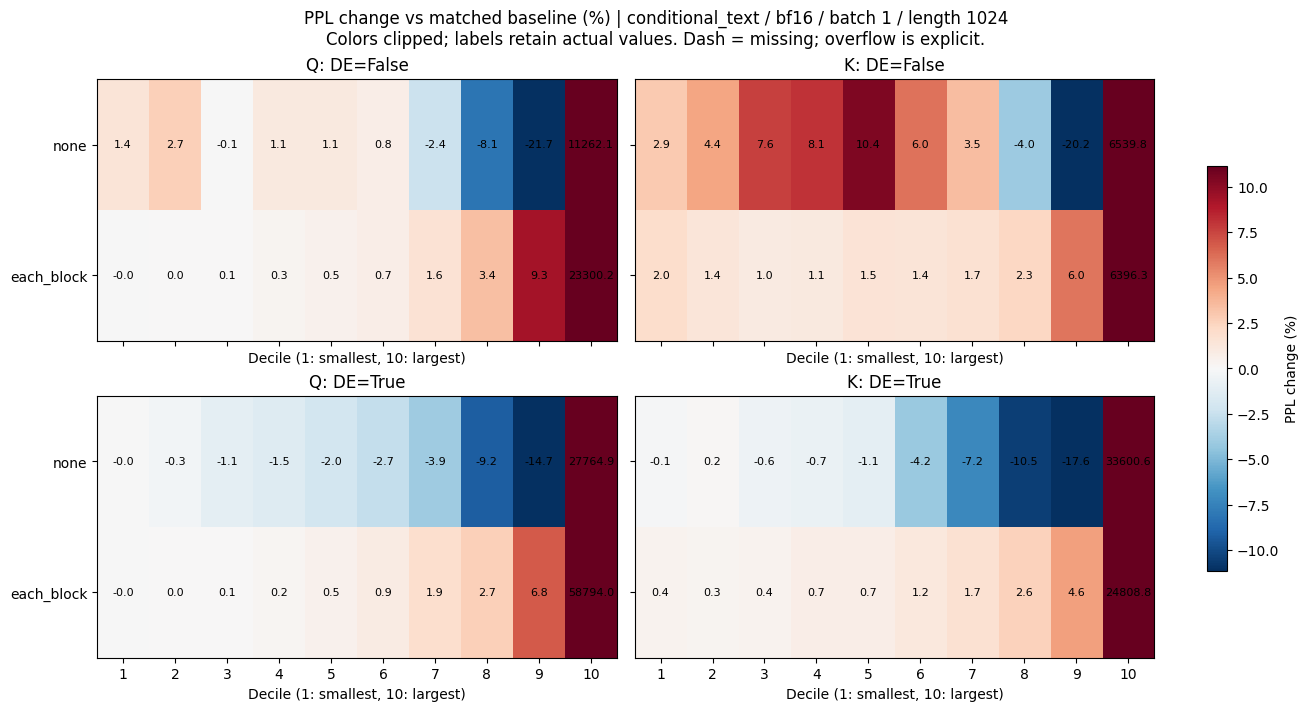

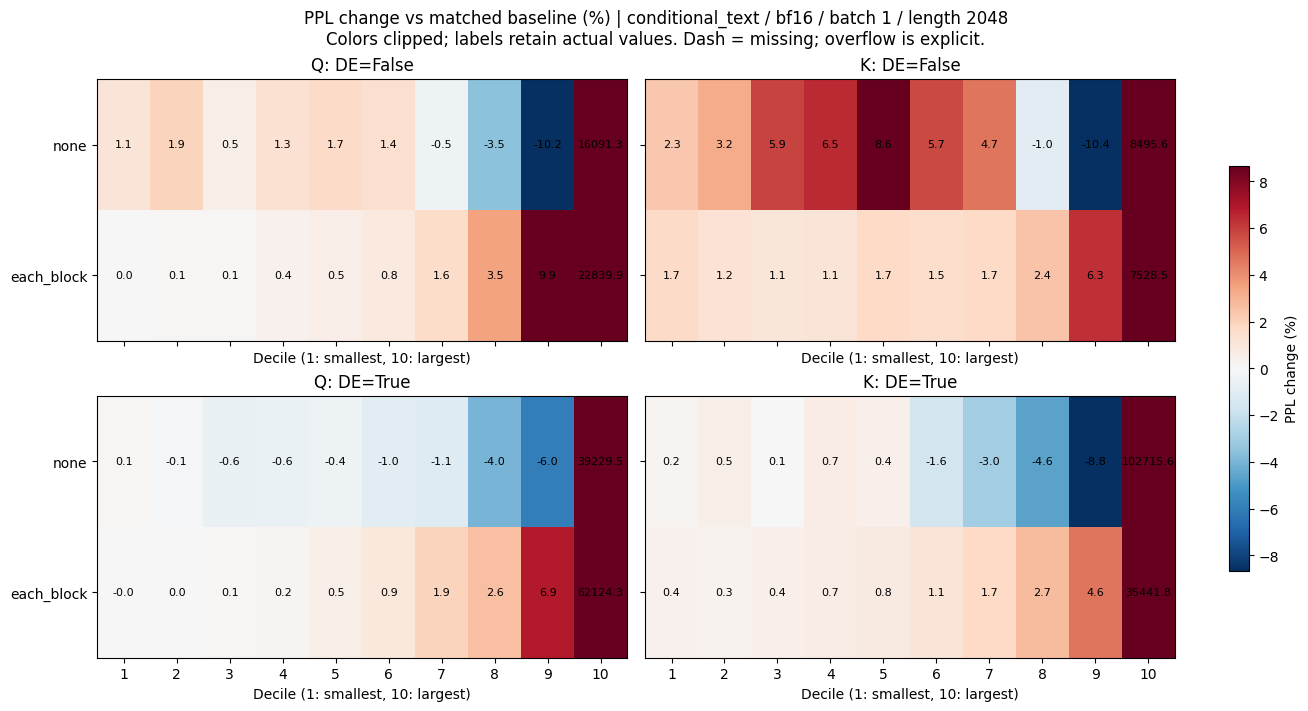

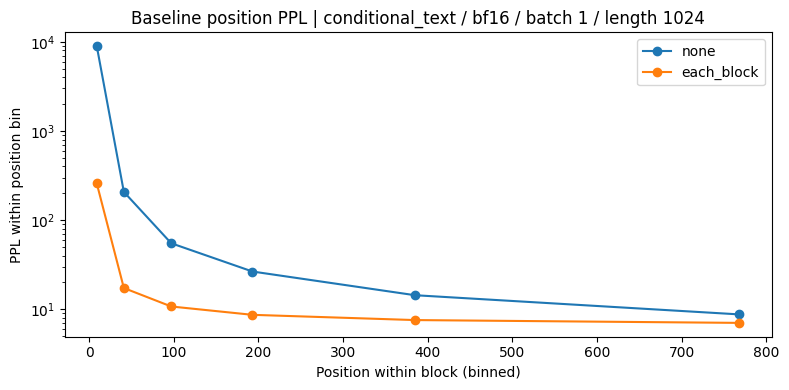

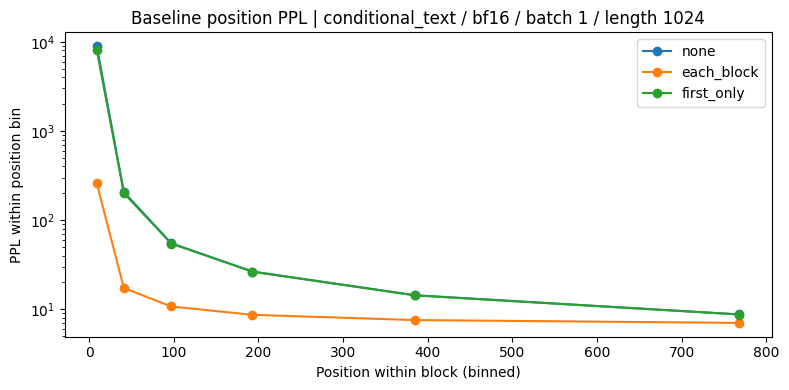

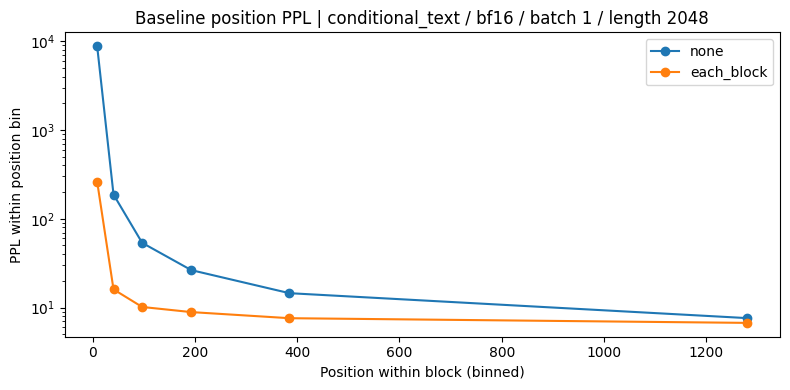

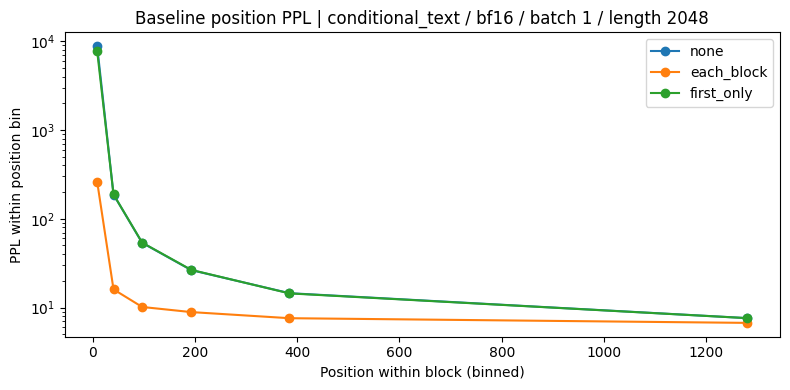

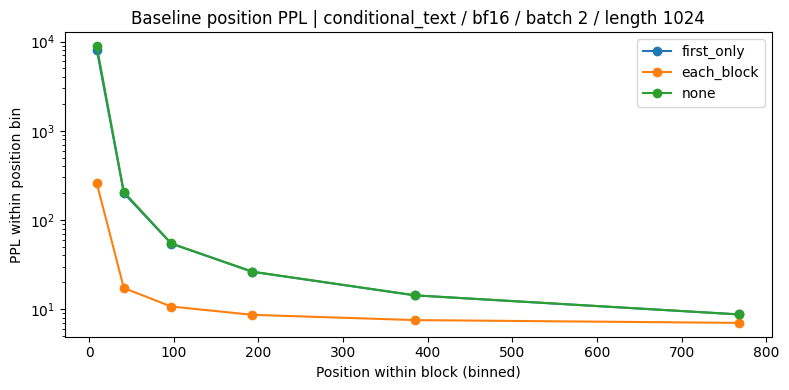

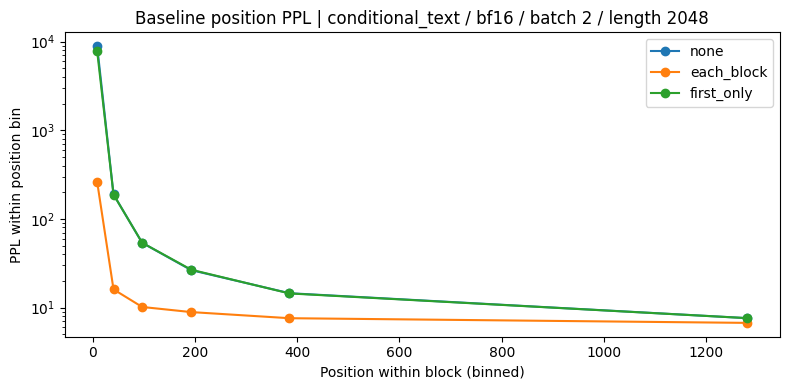

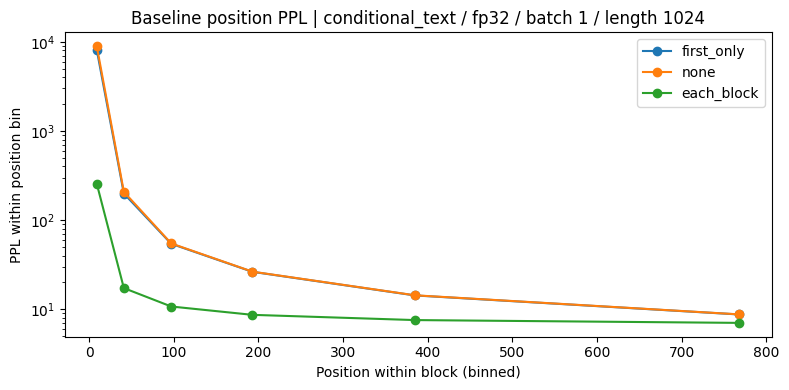

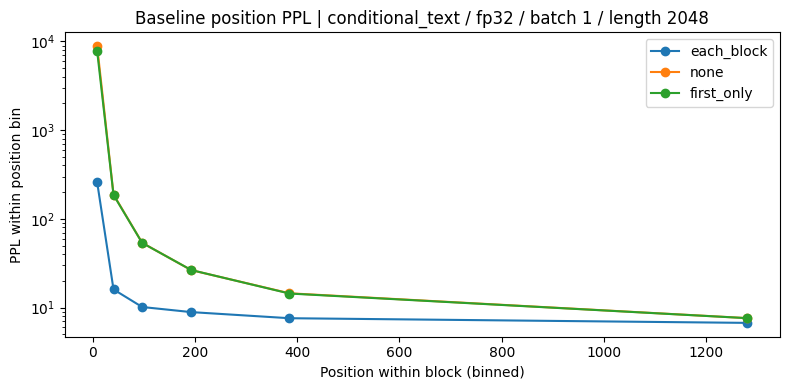

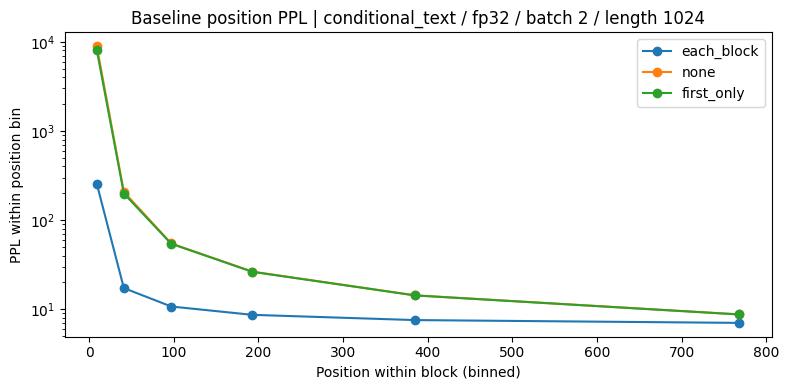

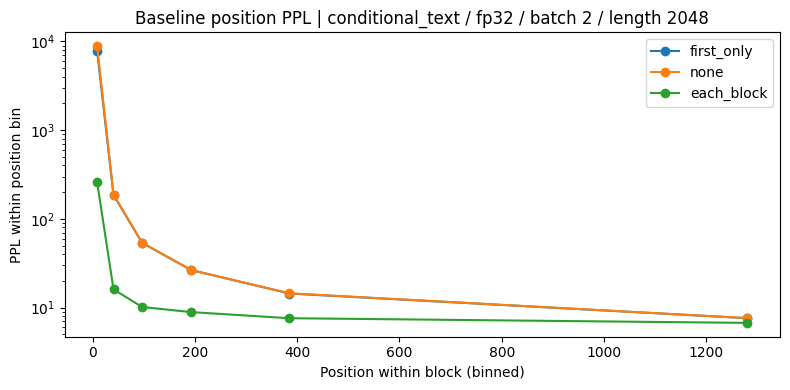

Saved analysis: /content/drive/MyDrive/TUS/hashiguchi/data/ibis2026_de_lra/gemma-qk-ppl-settings-grid-v1/analysis ; failures: 2


In [6]:
results=analyse()